Analysis on Human Lung SMI Data

In [28]:
import scanpy as sc
import numpy as np
import sctm
import squidpy as sq
import pandas as pd
import seaborn as sns
import scvi

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In this tutorial, we demonstrate how to analyse single cell level nanostring smi data. We transferred our data from the Giotto object located here https://nanostring.com/products/cosmx-spatial-molecular-imager/nsclc-ffpe-dataset. The processed dataset can be found at https://zenodo.org/records/10988053.

In [ ]:
adata = sc.read_h5ad(
    "../../../../STAMP/Reproducibility/ProcessedData/SMI_Lung/Lung5-3.h5ad"
)
adata.var_names_make_unique()

In [ ]:
adata.obsm['spatial'] = adata.obsm['spatial_raw']

In [ ]:
sc.pl.spatial(adata, spot_size = 0.03, color = 'cell_type')

In [ ]:
sc.pp.filter_cells(adata, min_counts=50)
sctm.pp.filter_genes(adata, 0.01)
sc.pp.highly_variable_genes(adata, n_top_genes=600, flavor="seurat_v3")

In [ ]:
# Build neighborhood graph
sq.gr.spatial_neighbors(adata, n_neighs=round(1/1000 * adata.n_obs))

In [ ]:
n_topics = 15
# Only hvgs and fit a total of 30 topics here
sctm.seed.seed_everything(0)
#
model = sctm.stamp.STAMP(
    adata[:, adata.var.highly_variable],
    n_topics=n_topics,
    gene_likelihood = "nb")
# uses gpu by default  to use cpu use device="cpu"
model.train(learning_rate = 0.01)

topic_prop = model.get_cell_by_topic()
beta = model.get_feature_by_topic()
for i in topic_prop.columns:
    adata.obs[i] = topic_prop[i]

Computing background frequencies


  0%|                                                                                                                        | 0/800 [00:00<?, ?it/s]/home/chengwei/miniconda3/envs/torch/lib/python3.9/site-packages/pyro/primitives.py:443: UserWarning: encoder.norm_topic.0.weight was not registered in the param store because requires_grad=False. You can silence this warning by calling my_module.train(False)
  warnings.warn(
Epoch Loss:241.257:  10%|████████▌                                                                             | 80/800 [1:16:56<11:35:13, 57.94s/it]

In [31]:
topic_prop = model.get_cell_by_topic()
beta = model.get_feature_by_topic()
# Add it into adata to visualize
for i in topic_prop.columns:
    adata.obs[i] = topic_prop[i]

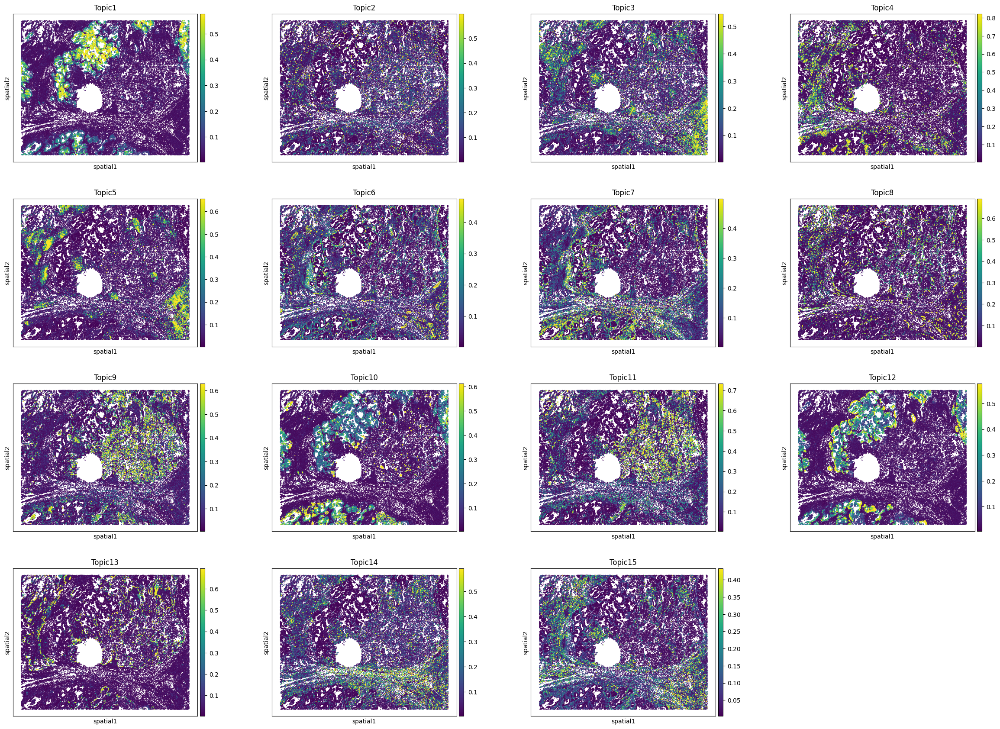

In [32]:
sctm.pl.spatial(adata, color = topic_prop.columns, size = 7, vmax = 'p99')

Analysis of topics with DISCO. In general, disco is very good at human celltypes that are not cancer related. Alternatively, we can also run other analysis such as over-enrichment analysis as well

In [33]:
celltypes = sctm.analysis.get_topic_disco(beta)

[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.8min
[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.8min
[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.8min
[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.9min
[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.9min
[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.9min
[Parallel(n_jobs=1)]: Done 3280 tasks      | elapsed:  2.9min


In [37]:
filtered = [] 
for i in celltypes.keys():
    # Filter out the low overlap
    df = celltypes[i].loc[celltypes[i].overlap > 5]
    # Filter only in lung
    df = df.loc[df['name'].str.contains("lung")]
    df["Topic"] = i
    filtered.append(df.head(3))

In [38]:
filtered = pd.concat(filtered)
filtered

,pval,or,name,gene,background,overlap,geneset,Topic
139,0.0,51.430,Goblet cell vs All others in lung,"EPCAM,S100P,AGR2,PSCA,ERBB3,KRT19,CEACAM6,KRT17",9264,8,166,Topic1
143,0.0,36.123,Airway basal cell vs All others in lung,"SLC2A1,EPCAM,DDR1,AGR2,CDH1,KRT19,KRT17,S100P,...",9264,10,348,Topic1
141,0.0,32.913,Club cell vs All others in lung,"EPCAM,SPINK1,AGR2,KRT19,ERBB3,CDH1",9264,6,166,Topic1
275,0.0,163.079,Mast cell vs All others in lung,"RGS1,RGS2,IL1RL1,CPA3,KIT,HPGDS,PTGS1,TPSB2,TP...",9264,17,344,Topic2
455,0.0,109.297,GZMK CD8 T cell vs All others in lung,"CD2,CD8A,DUSP2,TIGIT,FYB1,GZMK,GZMA,CD69,CCL5,...",9264,17,497,Topic3
456,0.0,73.825,GZMB CD8 T cell vs All others in lung,"CD2,CD8A,GZMA,CCL5,GZMK,STAT4,ITK,KLRB1,TIGIT,...",9264,15,398,Topic3
195,0.0,157.969,Plasma cell vs All others in lung,"IGKC,CD38,JCHAIN,MZB1,IRF4,CD27,IGHG2,IGHA1,IG...",9264,14,157,Topic4
192,0.0,59.285,Plasma cell vs Memory B cell in lung,"MZB1,JCHAIN,XBP1,IGHM,IGHA1,TNFRSF17,IGHG1,DUS...",9264,14,387,Topic4
494,0.0,85.616,Memory B cell vs All others in lung,"CD52,FCRLA,SELL,CD74,LTB,HLA-DQA1,MS4A1,IGHD,I...",9264,16,368,Topic5
324,0.0,118.625,Vascular smooth muscle cell vs All others in lung,"IGFBP5,IGFBP7,SPARCL1,PDGFRB,GPX3,CALD1,BGN,TA...",9264,17,461,Topic6


Plot out some of the top gene modules and topics

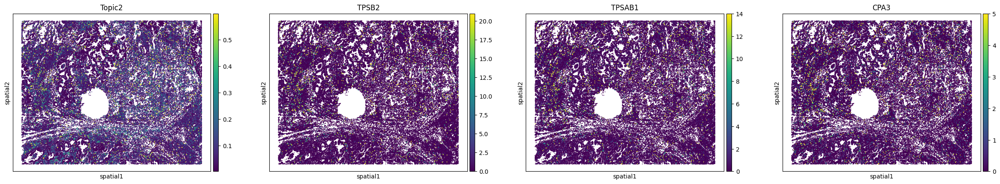

In [40]:
# Plot out Mast cells and top genes "Topic2"
sctm.pl.spatial(adata, color = ["Topic2"] + beta.nlargest(3, "Topic2").index.tolist(), size = 7, vmax ='p99')

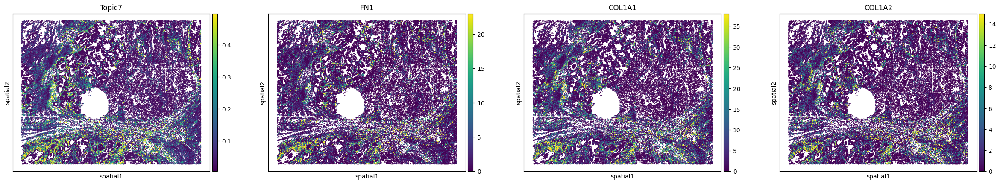

In [42]:
# Plot out CAF and top genes "Topic7"
sctm.pl.spatial(adata, color = ["Topic7"] + beta.nlargest(3, "Topic7").index.tolist(), size = 7, vmax ='p99')

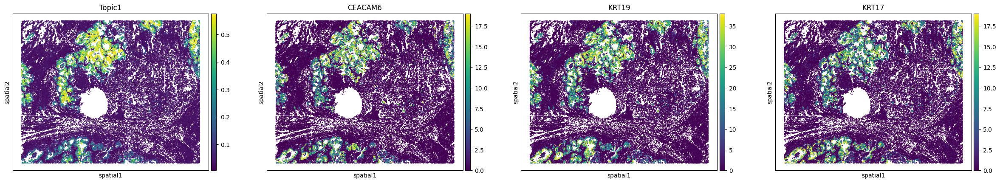

In [43]:
# Plot out tumor core and top genes "Topic1"
sctm.pl.spatial(adata, color = ["Topic1"] + beta.nlargest(3, "Topic1").index.tolist(), size = 7, vmax ='p99')

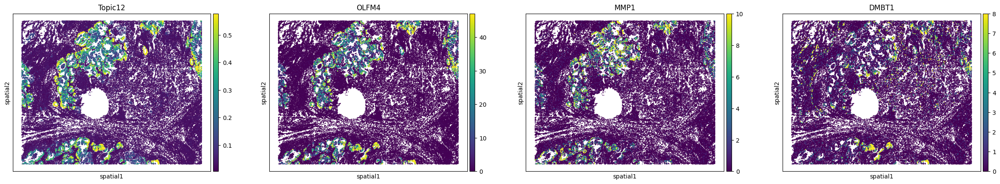

In [44]:
# Plot out tumor edge and top genes "Topic12"
sctm.pl.spatial(adata, color = ["Topic12"] + beta.nlargest(3, "Topic12").index.tolist(), size = 7, vmax ='p99')